# Exploring NASA MODIS climate data via GIBS

**Phase 1: setup.** This section builds the helpers used in the rest of the notebook:

1. **Catalog**: list every MODIS layer GIBS serves, with its available dates and color map.
2. **Fetch**: download a layer for one date and bounding box as a PNG (cached on disk).
3. **Decode**: convert pixel colors back to physical values using the layer's published color map.
4. **Check**: confirm the decoded values are physically sensible.

**Why decoding is needed.** GIBS serves *rendered images*, not raw science data. Each layer has a color map XML
that lists which RGB color stands for which value range. Every visible pixel matches a color map entry exactly,
so the reverse lookup is lossless, except that values come back binned (about 100–250 bins per layer).
Each bin is represented by its midpoint. The first and last bins are open-ended catch-alls (e.g. LST `[350 K, 652 K)`),
so they are represented by their inner edge, which clips extreme values.

In [1]:
import io
import re
import time
import hashlib
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

GIBS = "https://gibs.earthdata.nasa.gov"
WMS_URL = f"{GIBS}/wms/epsg4326/best/wms.cgi"
WMTS_CAPS_URL = f"{GIBS}/wmts/epsg4326/best/1.0.0/WMTSCapabilities.xml"

CACHE = Path("data/cache")
CACHE.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers["User-Agent"] = "dsc106-climate-exploration/0.1"

pd.set_option("display.max_colwidth", 80)

## 1. Layer catalog

The WMTS capabilities document (~5 MB) lists every GIBS layer with its date ranges and color map link.
It's cached locally. Pass `refresh=True` to download it again (GIBS adds new dates daily).

In [2]:
NS = {
    "w": "http://www.opengis.net/wmts/1.0",
    "ows": "http://www.opengis.net/ows/1.1",
    "xlink": "http://www.w3.org/1999/xlink",
}
HREF = f"{{{NS['xlink']}}}href"


def cached_get(url, path, refresh=False, **params):
    """GET `url` once and keep the bytes at `path`."""
    path = Path(path)
    if path.exists() and not refresh:
        return path.read_bytes()
    r = session.get(url, params=params or None, timeout=120)
    r.raise_for_status()
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(r.content)
    return r.content


def load_catalog(refresh=False):
    xml = cached_get(WMTS_CAPS_URL, CACHE / "WMTSCapabilities.xml", refresh=refresh)
    root = ET.fromstring(xml)
    rows = []
    for layer in root.iter(f"{{{NS['w']}}}Layer"):
        hrefs = [m.get(HREF) or "" for m in layer.findall("ows:Metadata", NS)]
        rows.append({
            "layer": layer.find("ows:Identifier", NS).text,
            "title": layer.find("ows:Title", NS).text,
            "format": layer.find("w:Format", NS).text,
            "resolution": layer.find("w:TileMatrixSetLink/w:TileMatrixSet", NS).text,
            "time_ranges": [v.text for v in layer.findall("w:Dimension/w:Value", NS)],
            "colormap_url": next((h for h in hrefs if "/colormaps/v1.3/" in h), None),
            "legend_url": next((lg.get(HREF) for lg in layer.iter(f"{{{NS['w']}}}LegendURL")
                                if lg.get(HREF, "").endswith("_H.svg")), None),
        })
    return pd.DataFrame(rows).set_index("layer")


catalog = load_catalog()
modis = catalog[catalog.index.str.startswith("MODIS_")].copy()
print(f"{len(catalog)} GIBS layers, {len(modis)} MODIS layers")

1332 GIBS layers, 250 MODIS layers


Date ranges are written as `start/end/period`, e.g. `2000-03-01/2026-10-01/P1M`. A layer can list several ranges,
and the spaces between them are **gaps with no data**. `layer_dates()` expands them into individual dates.

In [3]:
PERIOD_RE = re.compile(r"^P(\d+)([DMY])$")


def expand_range(spec):
    """'2000-03-01/2000-06-01/P1M' -> DatetimeIndex of every date in the range."""
    parts = spec.split("/")
    if len(parts) == 1:
        return pd.DatetimeIndex([parts[0][:10]])
    start, end, period = parts
    m = PERIOD_RE.match(period)
    if m is None:                       # sub-daily periods (PT10M etc.): just keep the endpoints
        return pd.DatetimeIndex([start[:10], end[:10]])
    n, unit = int(m.group(1)), m.group(2)
    freq = {"D": f"{n}D", "M": f"{n}MS", "Y": f"{n}YS"}[unit]
    return pd.date_range(start[:10], end[:10], freq=freq)


def layer_dates(layer):
    ranges = catalog.loc[layer, "time_ranges"]
    return pd.DatetimeIndex(sorted(set().union(*[expand_range(r) for r in ranges])))


def summarize(layer):
    d = layer_dates(layer)
    period = catalog.loc[layer, "time_ranges"][0].split("/")[-1]
    out = {"first": d.min().date(), "last": d.max().date(), "n_dates": len(d), "period": period}
    if period == "P1M":                 # count missing months inside the span
        full = pd.date_range(d.min(), d.max(), freq="MS")
        missing = full.difference(d)
        out["n_missing"] = len(missing)
        out["missing_example"] = ", ".join(m.strftime("%Y-%m") for m in missing[:4]) + (" …" if len(missing) > 4 else "")
    return out

### Monthly MODIS layers

Monthly composites are the most useful starting point for a story over time: there are 25+ years of them and fewer cloud gaps than daily data.
`n_missing` counts months with no data between the first and last date.

In [4]:
monthly = [l for l in modis.index if any(r.endswith("/P1M") for r in modis.loc[l, "time_ranges"])]
monthly_summary = pd.DataFrame({l: summarize(l) for l in monthly}).T
monthly_summary["title"] = modis.loc[monthly, "title"]
monthly_summary["has_colormap"] = modis.loc[monthly, "colormap_url"].notna()
monthly_summary.sort_values("n_dates", ascending=False)

,first,last,n_dates,period,n_missing,missing_example,title,has_colormap
MODIS_Terra_L3_Land_Surface_Temp_Monthly_CMG_Day_TES,2000-02-01,2026-10-01,321,P1M,0,,"Land Surface Temperature (ASTER TES L3, Monthly, Day, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_CMG_Night_TES,2000-02-01,2026-10-01,321,P1M,0,,"Land Surface Temperature (ASTER TES L3, Monthly, Night, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day,2000-03-01,2026-10-01,320,P1M,0,,"Land Surface Temperature (L3, Monthly, Day, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_Night,2000-03-01,2026-10-01,320,P1M,0,,"Land Surface Temperature (L3, Monthly, Night, MODIS, Terra)",True
MODIS_Terra_L3_EVI_Monthly,2000-03-01,2026-10-01,319,P1M,1,2025-04,"Enhanced Vegetation Index (L3, Monthly, MODIS, Terra)",True
MODIS_Terra_L3_NDVI_Monthly,2000-03-01,2026-10-01,319,P1M,1,2025-04,"Vegetation Index (L3, Monthly, MODIS, Terra)",True
MODIS_Terra_L3_Snow_Cover_Monthly_Average_Pct,2000-03-01,2026-10-01,314,P1M,6,"2000-08, 2001-06, 2002-03, 2003-12 …","Snow Cover (L3, Monthly Average Percent, MODIS, Terra)",True
MODIS_Terra_L3_SST_Thermal_4km_Night_Monthly,2000-08-01,2026-04-01,304,P1M,5,"2022-10, 2022-12, 2023-01, 2024-01 …","Sea Surface Temperature (L3, Night, Monthly, Thermal, 4 km, MODIS, Terra)",True
MODIS_Terra_L3_SST_MidIR_4km_Night_Monthly,2000-08-01,2026-04-01,303,P1M,6,"2022-10, 2022-12, 2023-01, 2023-06 …","Sea Surface Temperature (L3, Night, Monthly, Mid Infrared, 4 km, MODIS, Terra)",True
MODIS_Terra_L3_SST_Thermal_9km_Night_Monthly,2000-08-01,2026-04-01,303,P1M,6,"2022-10, 2022-12, 2023-01, 2023-06 …","Sea Surface Temperature (L3, Night, Monthly, Thermal, 9 km, MODIS, Terra)",True


Search the full MODIS catalog by keyword:

In [5]:
def find_layers(pattern):
    hits = modis[modis.index.str.contains(pattern, case=False) | modis["title"].str.contains(pattern, case=False)]
    return hits[["title", "format", "resolution"]].assign(
        first=[layer_dates(l).min().date() for l in hits.index],
        last=[layer_dates(l).max().date() for l in hits.index],
    )

find_layers("snow")

,title,format,resolution,first,last
layer,,,,,
MODIS_Aqua_L3_Snow_Cover_Monthly_Average_Pct,"Snow Cover (L3, Monthly Average Percent, MODIS, Aqua)",image/png,2km,2002-07-04,2026-10-01
MODIS_Terra_L3_Snow_Cover_Monthly_Average_Pct,"Snow Cover (L3, Monthly Average Percent, MODIS, Terra)",image/png,2km,2000-03-01,2026-10-01
MODIS_Aqua_L3_NDSI_Snow_Cover_Daily,"Snow Cover (Normalized Difference Snow Index, L3, Daily, MODIS, Aqua)",image/png,500m,2002-07-04,2026-11-02
MODIS_Terra_L3_NDSI_Snow_Cover_Daily,"Snow Cover (Normalized Difference Snow Index, L3, Daily, MODIS, Terra)",image/png,500m,2000-02-24,2026-11-02
MODIS_Aqua_NDSI_Snow_Cover,"Snow Cover (Normalized Difference Snow Index, MODIS, Aqua)",image/png,500m,2002-07-03,2026-11-04
MODIS_Terra_NDSI_Snow_Cover,"Snow Cover (Normalized Difference Snow Index, MODIS, Terra)",image/png,500m,2000-02-24,2026-11-05
MODIS_Aqua_L3_Snow_Extent_8Day,"Snow Extent (L3, 8-Day, MODIS, Aqua)",image/png,500m,2002-07-04,2026-10-24
MODIS_Terra_L3_Snow_Extent_8Day,"Snow Extent (L3, 8-Day, MODIS, Terra)",image/png,500m,2000-02-26,2026-10-24


## 2. Color maps

Each color map XML has one or more `<ColorMap>` blocks. Entries take several forms:

| Form | Example | Decoded as |
|---|---|---|
| range | `[0.02,200.00)` | midpoint (inner edge for the first and last bins) |
| single value | `[42]` or `42` | that value |
| open-ended | `[-INF,0.00)` / `[32.00,+INF)` | the finite edge |
| `nodata="true"` | | NaN |
| no `value` (classification) | e.g. "Cloud", "Ocean" in the snow layer | NaN, with its label kept in `.classes` |

**Caveat:** `transparent="true"` entries come back as fully transparent pixels, which look the same as "no data".
For example, NDVI below −0.1 (water) and **0% snow cover** are both transparent, so they decode to NaN.
Keep this in mind before averaging snow cover.

In [6]:
NUM = r"([+-]?(?:INF|\d*\.?\d+(?:[eE][+-]?\d+)?))"
RANGE_RE = re.compile(rf"^\s*[\[(]{NUM}\s*,\s*{NUM}\s*[\])]\s*$")
SINGLE_RE = re.compile(rf"^\s*\[?{NUM}\]?\s*$")


def _num(s):
    s = s.upper()
    return float("inf") if s in ("INF", "+INF") else float("-inf") if s == "-INF" else float(s)


def rgb_key(r, g, b):
    return (np.asarray(r, np.int64) << 16) | (np.asarray(g, np.int64) << 8) | np.asarray(b, np.int64)


@dataclass
class Colormap:
    title: str
    units: str | None
    keys: np.ndarray          # packed RGB, sorted
    values: np.ndarray        # decoded value per key (NaN = nodata / class)
    classes: dict = field(default_factory=dict)   # packed RGB -> label for classification colors
    n_numeric: int = 0

    def __repr__(self):
        lo, hi = np.nanmin(self.values), np.nanmax(self.values)
        return (f"Colormap({self.title!r}, units={self.units!r}, {self.n_numeric} numeric bins "
                f"[{lo:g} … {hi:g}], {len(self.classes)} classes)")


def parse_colormap(xml_bytes):
    root = ET.fromstring(xml_bytes)
    keys, values, classes = [], [], {}
    title = units = None
    numeric = []                                   # (index, lo, hi) to fix up edge bins afterwards
    for cm in root.iter("ColorMap"):
        tooltips = {le.get("id"): le.get("tooltip") for le in cm.iter("LegendEntry")}
        for e in cm.iter("ColorMapEntry"):
            key = int(rgb_key(*map(int, e.get("rgb").split(","))))
            v = e.get("value")
            if e.get("nodata") == "true" or v is None:
                keys.append(key); values.append(np.nan)
                classes[key] = e.get("label") or tooltips.get(e.get("ref")) or ("No Data" if e.get("nodata") == "true" else "class")
                continue
            if title is None:
                title, units = cm.get("title"), cm.get("units")
            if (m := RANGE_RE.match(v)):
                lo, hi = _num(m.group(1)), _num(m.group(2))
                numeric.append((len(values), lo, hi))
                val = lo if np.isinf(hi) else hi if np.isinf(lo) else (lo + hi) / 2
            elif (m := SINGLE_RE.match(v)):
                val = _num(m.group(1))
            else:
                raise ValueError(f"unrecognized colormap value {v!r}")
            keys.append(key); values.append(val)
    # first/last numeric range bins are catch-alls: use their inner edge
    if len(numeric) >= 2:
        numeric.sort(key=lambda t: t[1])
        (i0, _, hi0), (i1, lo1, _) = numeric[0], numeric[-1]
        values[i0], values[i1] = (hi0 if np.isfinite(hi0) else values[i0]), (lo1 if np.isfinite(lo1) else values[i1])
    keys, values = np.array(keys, np.int64), np.array(values, float)
    order = np.argsort(keys, kind="stable")
    keys, idx = np.unique(keys[order], return_index=True)   # keep first entry if a color repeats
    values = values[order][idx]
    return Colormap(title, units, keys, values, classes, int(np.isfinite(values).sum()))


def load_colormap(layer):
    url = catalog.loc[layer, "colormap_url"]
    if url is None:
        raise ValueError(f"{layer} has no color map (it may be imagery or vector data)")
    return parse_colormap(cached_get(url, CACHE / "colormaps" / Path(url).name))


load_colormap("MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day")

Colormap('Land Surface Temperature', units='K', 252 numeric bins [200 … 350.02], 1 classes)

## 3. Fetching and decoding grids

`get_grid()` requests the layer from the GIBS **WMS** endpoint for any bounding box and pixel size, then decodes it.

- The default is a global 720×360 image, i.e. **0.5° per pixel**. That's a good resolution for exploring.
  For a region, pass a smaller `bbox` and a larger `width` to zoom in.
- `bbox` is `(west, south, east, north)` in degrees. Note that WMS 1.3.0 with EPSG:4326 expects *lat, lon* order;
  the function handles the conversion.
- PNGs are cached under `data/cache/wms/<layer>/`, so re-running the notebook makes no network requests.

The result is a small `Grid` object with `.values`, `.lats`, `.lons`, `.sel()` for cropping,
an area-weighted `.mean()`, and `.plot()`.

In [7]:
GLOBAL = (-180, -90, 180, 90)


def fetch_png(layer, when, bbox=GLOBAL, width=720, height=None, refresh=False):
    """Return the WMS image as an (H, W, 4) uint8 RGBA array."""
    west, south, east, north = bbox
    if height is None:                               # keep pixels square in degrees
        height = max(1, round(width * (north - south) / (east - west)))
    when = pd.Timestamp(when).strftime("%Y-%m-%d")
    tag = hashlib.md5(f"{bbox}".encode()).hexdigest()[:8]
    path = CACHE / "wms" / layer / f"{when}_{tag}_{width}x{height}.png"
    if not path.exists() or refresh:
        params = dict(SERVICE="WMS", REQUEST="GetMap", VERSION="1.3.0", LAYERS=layer,
                      CRS="EPSG:4326", BBOX=f"{south},{west},{north},{east}",
                      WIDTH=width, HEIGHT=height, FORMAT="image/png", TIME=when)
        for attempt in range(3):
            r = session.get(WMS_URL, params=params, timeout=120)
            if r.ok and r.headers.get("content-type", "").startswith("image/"):
                break
            time.sleep(2 ** attempt)
        else:
            raise RuntimeError(f"GIBS error for {layer} @ {when}: {r.status_code} {r.text[:300]}")
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(r.content)
    return np.array(Image.open(path).convert("RGBA"))


def decode(rgba, cmap):
    """Map RGBA pixels to values. Transparent / nodata / unmatched -> NaN."""
    key = rgb_key(rgba[..., 0], rgba[..., 1], rgba[..., 2])
    pos = np.clip(np.searchsorted(cmap.keys, key), 0, len(cmap.keys) - 1)
    matched = cmap.keys[pos] == key
    opaque = rgba[..., 3] > 0
    values = np.where(matched & opaque, cmap.values[pos], np.nan)
    unmatched = (opaque & ~matched).sum()
    return values, unmatched


@dataclass
class Grid:
    layer: str
    date: pd.Timestamp
    values: np.ndarray
    lats: np.ndarray       # pixel-center latitudes, north -> south
    lons: np.ndarray       # pixel-center longitudes, west -> east
    units: str | None = None
    title: str | None = None

    @property
    def extent(self):
        dlat, dlon = abs(self.lats[1] - self.lats[0]), abs(self.lons[1] - self.lons[0])
        return (self.lons[0] - dlon / 2, self.lons[-1] + dlon / 2, self.lats[-1] - dlat / 2, self.lats[0] + dlat / 2)

    def sel(self, lat=None, lon=None):
        """Crop to lat=(south, north), lon=(west, east)."""
        r = np.ones(len(self.lats), bool) if lat is None else (self.lats >= lat[0]) & (self.lats <= lat[1])
        c = np.ones(len(self.lons), bool) if lon is None else (self.lons >= lon[0]) & (self.lons <= lon[1])
        return Grid(self.layer, self.date, self.values[np.ix_(r, c)], self.lats[r], self.lons[c], self.units, self.title)

    def mean(self):
        """Area-weighted mean (cos latitude) over pixels with data."""
        w = np.broadcast_to(np.cos(np.deg2rad(self.lats))[:, None], self.values.shape)
        ok = np.isfinite(self.values)
        return float((self.values[ok] * w[ok]).sum() / w[ok].sum()) if ok.any() else np.nan

    def coverage(self):
        return float(np.isfinite(self.values).mean())

    def plot(self, ax=None, **kw):
        ax = ax or plt.gca()
        im = ax.imshow(self.values, extent=self.extent, origin="upper", interpolation="nearest", **kw)
        ax.set_title(f"{self.title or self.layer}\n{self.date:%Y-%m-%d}", fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.7, label=self.units or "")
        return im


_cmaps = {}

def get_grid(layer, when, bbox=GLOBAL, width=720, height=None, refresh=False):
    if layer not in _cmaps:
        _cmaps[layer] = load_colormap(layer)
    cmap = _cmaps[layer]
    rgba = fetch_png(layer, when, bbox, width, height, refresh)
    values, unmatched = decode(rgba, cmap)
    if unmatched:
        print(f"warning: {unmatched} opaque pixels in {layer} @ {when} did not match the color map")
    h, w = values.shape
    west, south, east, north = bbox
    lats = north - (np.arange(h) + 0.5) * (north - south) / h
    lons = west + (np.arange(w) + 0.5) * (east - west) / w
    return Grid(layer, pd.Timestamp(when), values, lats, lons, cmap.units, cmap.title)

## 4. Checks

Decode a few layers and compare them with known values:

| Check | Expected |
|---|---|
| Sahara daytime land surface temperature, July | ≈ 320–330 K (~50 °C) |
| Antarctic interior daytime LST, July | ≈ 200–230 K (very cold; "day" means the ~10:30 am overpass, not sunlight) |
| Amazon NDVI | > 0.7 (dense forest) |
| Sahara NDVI | < 0.15 (bare desert) |
| Equatorial Pacific SST | ≈ 26–30 °C |
| Every visible pixel matches a color map entry | 0 warnings |

In [8]:
LST = "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day"
NDVI = "MODIS_Terra_L3_NDVI_Monthly"
SST = "MODIS_Terra_L3_SST_Thermal_4km_Day_Monthly"
WHEN = "2020-07-01"

lst = get_grid(LST, WHEN)
ndvi = get_grid(NDVI, WHEN)
sst = get_grid(SST, WHEN)

SAHARA = dict(lat=(18, 30), lon=(-10, 30))
AMAZON = dict(lat=(-10, 0), lon=(-70, -55))
ANTARCTICA = dict(lat=(-90, -75))
EQ_PACIFIC = dict(lat=(-5, 5), lon=(-170, -120))

checks = pd.DataFrame([
    ("Sahara LST (K)",         lst.sel(**SAHARA).mean(),           lambda v: 305 < v < 340),
    ("Antarctica LST (K)",     lst.sel(**ANTARCTICA).mean(),       lambda v: 190 < v < 240),
    ("Amazon NDVI",            ndvi.sel(**AMAZON).mean(),          lambda v: v > 0.7),
    ("Sahara NDVI",            ndvi.sel(**SAHARA).mean(),          lambda v: v < 0.15),
    ("Eq. Pacific SST (°C)",   sst.sel(**EQ_PACIFIC).mean(),       lambda v: 25 < v < 31),
], columns=["check", "value", "test"])
checks["pass"] = [t(v) for t, v in zip(checks["test"], checks["value"])]
checks = checks.drop(columns="test")
assert checks["pass"].all(), checks
checks

,check,value,pass
0,Sahara LST (K),322.172330,True
1,Antarctica LST (K),219.669737,True
2,Amazon NDVI,0.831267,True
3,Sahara NDVI,0.100836,True
4,Eq. Pacific SST (°C),27.160199,True


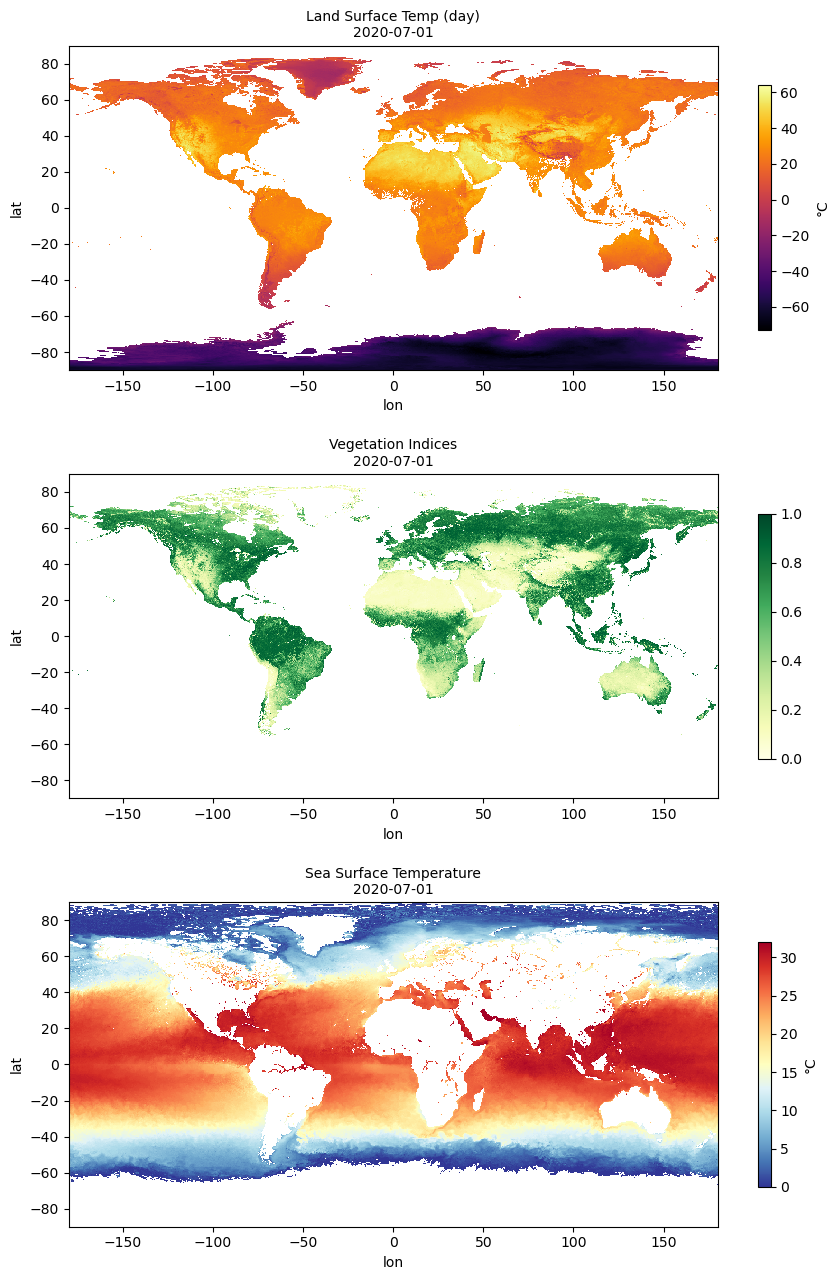

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9, 13))
lst_c = Grid(lst.layer, lst.date, lst.values - 273.15, lst.lats, lst.lons, "°C", "Land Surface Temp (day)")
lst_c.plot(axes[0], cmap="inferno")
ndvi.plot(axes[1], cmap="YlGn", vmin=0, vmax=1)
sst.plot(axes[2], cmap="RdYlBu_r")
for ax in axes:
    ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.tight_layout()

### A first time series

A quick end-to-end test over time: the area-weighted mean of Sahara daytime land surface temperature for every July.
Expect year-to-year variation of a degree or two. This is 26 requests on the first run and instant after that.

count    27.00
mean     47.69
std       1.52
min      41.77
25%      47.81
50%      48.05
75%      48.46
max      49.02
Name: Sahara July LST (°C), dtype: float64

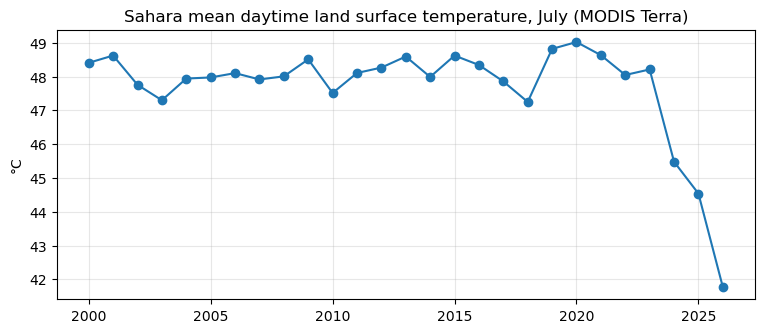

In [10]:
julys = [d for d in layer_dates(LST) if d.month == 7]
sahara_july = pd.Series({d.year: get_grid(LST, d).sel(**SAHARA).mean() - 273.15 for d in julys}, name="Sahara July LST (°C)")

ax = sahara_july.plot(marker="o", figsize=(9, 3.5))
ax.set_ylabel("°C"); ax.set_title("Sahara mean daytime land surface temperature, July (MODIS Terra)")
ax.grid(alpha=0.3)
sahara_july.describe().round(2)

### ⚠️ Caution: orbit drift after 2022

The July series above **drops by about 6 °C from 2023 to 2026**. This is a problem with the instrument, not climate.
Terra and Aqua are past their planned mission life and are no longer held in their usual orbits, so the local time
at which they pass overhead is changing:

- **Terra** used to pass at about 10:30 am / 10:30 pm and now passes **earlier**. An earlier morning pass sees cooler
  ground, and an earlier evening pass sees warmer ground. So Terra *day* LST falls and Terra *night* LST rises.
- **Aqua** used to pass at about 1:30 pm / 1:30 am and now passes **later**, so its *day* LST starts falling too.

The check below compares all four day/night series for the Sahara in July.

,Terra day,Terra night,Aqua day,Aqua night
2018,47.2,27.5,51.2,24.9
2019,48.8,28.1,53.2,25.5
2020,49.0,28.2,53.3,25.6
2021,48.6,28.3,52.8,25.7
2022,48.0,28.1,53.1,25.1
2023,48.2,29.4,53.9,26.0
2024,45.5,29.8,52.2,26.1
2025,44.5,30.3,52.6,25.6
2026,41.8,30.9,50.5,25.2


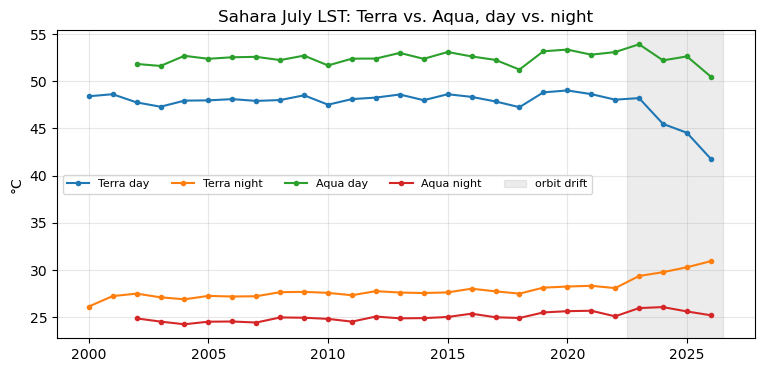

In [11]:
lst_layers = {
    "Terra day": "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day",
    "Terra night": "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Night",
    "Aqua day": "MODIS_Aqua_L3_Land_Surface_Temp_Monthly_Day",
    "Aqua night": "MODIS_Aqua_L3_Land_Surface_Temp_Monthly_Night",
}
drift = pd.DataFrame({
    name: {d.year: get_grid(L, d).sel(**SAHARA).mean() - 273.15 for d in layer_dates(L) if d.month == 7}
    for name, L in lst_layers.items()
})
ax = drift.plot(marker=".", figsize=(9, 4))
ax.axvspan(2022.5, drift.index.max() + 0.5, color="grey", alpha=0.15, label="orbit drift")
ax.set_ylabel("°C"); ax.set_title("Sahara July LST: Terra vs. Aqua, day vs. night"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
drift.loc[2018:].round(1)

**What this means for the project:** treat **2000/2002–2022** as the reliable period for trends in anything that
depends on time of day (mainly land surface temperature, and to a lesser degree SST and cloud layers).
If a story needs recent years, either show the drift openly or use a quantity that changes less with time of day.
NDVI and snow come from composites over many days and are less affected, but check them the same way in Phase 2.

## Phase 1 summary

Helpers available for the next phases:

| Helper | Purpose |
|---|---|
| `catalog`, `modis`, `monthly_summary` | layer metadata and date coverage |
| `find_layers("keyword")` | search MODIS layers |
| `layer_dates(layer)` | every available date (gaps excluded) |
| `load_colormap(layer)` | parsed color-to-value lookup |
| `get_grid(layer, date, bbox, width)` | decoded `Grid` (`.values`, `.sel()`, `.mean()`, `.coverage()`, `.plot()`) |

**Known data issues:** satellite orbit drift after 2022 (above), transparent values such as 0% snow decode to NaN,
and values are binned (about 0.6 K steps for LST).

**Next:** Phase 2 below, which focuses on temperature anomalies vs. vegetation change.

# Phase 2: Temperature anomalies vs. vegetation change

**Priority:** where has the land surface become unusually warm, and does that line up with where vegetation is
changing (greening, browning, forest loss)?

| Step | Output |
|---|---|
| 2.1 | Monthly data for 2001–2022: daytime land surface temperature (LST) and NDVI, MODIS Terra, 0.5° grid |
| 2.2 | **Anomaly maps**: difference from a 2001–2010 baseline, as a decade map, one map per year, and a trend map |
| 2.3 | **Vegetation change**: NDVI trends plus *land cover* change (forest, cropland, …) from the yearly IGBP classification |
| 2.4 | **Comparison**: per-pixel correlation, trend-vs-trend plots, results by land-cover type, and regional hotspots |

**Choices**
- **2001–2022 only.** From 2023 on, Terra's drifting orbit makes daytime LST artificially cooler (see Phase 1).
- **Anomaly = value − average for that calendar month in 2001–2010**, then averaged over each year.
  A year counts only if it has ≥ 6 valid months, which avoids bias from long gaps such as polar night or persistent cloud.
- **Daytime LST**, because vegetation cools the surface through evaporation mostly during the day, so that's where the two signals interact.
- Maps are cropped to 60°S–85°N (vegetated land only). **Gray = no data** (ocean, ice, or too few months), so it isn't
  mistaken for "no change". The middle of each color scale is near-white.

In [12]:
import warnings
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="divide by zero")

plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#888", "axes.labelcolor": "#333", "xtick.color": "#555", "ytick.color": "#555",
    "grid.color": "#ddd", "grid.linewidth": 0.6,
})
NODATA_COLOR = "#c9c9c9"
LAT_VIEW = (-60, 85)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # categorical slots 1-4, fixed order

YEARS = np.arange(2001, 2023)
BASE = (2001, 2010)
RECENT = (2013, 2022)


def get_stack(layer, dates, bbox=GLOBAL, width=720, workers=6):
    """Decoded values for many dates -> (n, H, W) float32 array + a template Grid (lats/lons)."""
    dates = list(pd.DatetimeIndex(dates))
    with ThreadPoolExecutor(workers) as ex:              # fill the cache in parallel
        list(ex.map(lambda d: fetch_png(layer, d, bbox, width), dates))
    grids = [get_grid(layer, d, bbox, width) for d in dates]
    return np.stack([g.values.astype(np.float32) for g in grids]), grids[0]


def monthly_cube(layer, start="2001-01", end="2022-12"):
    months = pd.date_range(start, end, freq="MS")
    avail = months.intersection(layer_dates(layer))
    stack, tmpl = get_stack(layer, avail)
    cube = np.full((len(months),) + stack.shape[1:], np.nan, np.float32)
    cube[months.get_indexer(avail)] = stack
    return months, cube, tmpl


def annual_anomalies(months, cube, base=BASE, min_months=6):
    """Monthly values -> (years, annual-mean anomaly vs. per-calendar-month baseline). Modifies `cube` in place."""
    yr, mo = months.year.values, months.month.values
    in_base = (yr >= base[0]) & (yr <= base[1])
    clim = np.stack([np.nanmean(cube[in_base & (mo == m)], axis=0) for m in range(1, 13)])
    for m in range(1, 13):
        cube[mo == m] -= clim[m - 1]
    years = np.unique(yr)
    annual = np.stack([np.nanmean(cube[yr == y], axis=0) for y in years])
    n_valid = np.stack([np.isfinite(cube[yr == y]).sum(axis=0) for y in years])
    annual[n_valid < min_months] = np.nan
    return years, annual, clim


def period_mean(years, annual, period):
    sel = (years >= period[0]) & (years <= period[1])
    return np.nanmean(annual[sel], axis=0)


def trend_per_decade(years, annual, min_years=15):
    """Per-pixel least-squares slope (units per decade), ignoring NaN years."""
    t = years.astype(float)[:, None, None]
    ok = np.isfinite(annual)
    n = ok.sum(axis=0)
    tm = np.where(ok, t, 0).sum(axis=0) / n
    ym = np.where(ok, annual, 0).sum(axis=0) / n
    cov = np.where(ok, (t - tm) * (annual - ym), 0).sum(axis=0)
    var = np.where(ok, (t - tm) ** 2, 0).sum(axis=0)
    slope = 10 * cov / var
    slope[n < min_years] = np.nan
    return slope


def pixel_corr(a, b, min_n=15):
    """Per-pixel Pearson r between two (year, H, W) stacks."""
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = np.where(ok, a, np.nan), np.where(ok, b, np.nan)
    da, db = a - np.nanmean(a, axis=0), b - np.nanmean(b, axis=0)
    r = np.nansum(da * db, axis=0) / np.sqrt(np.nansum(da**2, axis=0) * np.nansum(db**2, axis=0))
    r[ok.sum(axis=0) < min_n] = np.nan
    return r


def sym_limit(*arrays, q=98):
    v = np.concatenate([np.abs(a[np.isfinite(a)]) for a in arrays])
    return float(np.percentile(v, q))


def map_panel(ax, values, tmpl, cmap, vlim, title="", colorbar_label=None, symmetric=True, boxes=None):
    ax.set_facecolor(NODATA_COLOR)
    vmin, vmax = (-vlim, vlim) if symmetric else vlim
    im = ax.imshow(values, extent=tmpl.extent, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_ylim(*LAT_VIEW); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title)
    for name, (lat, lon) in (boxes or {}).items():
        ax.add_patch(plt.Rectangle((lon[0], lat[0]), lon[1] - lon[0], lat[1] - lat[0], fill=False, lw=1, ec="#111"))
        ax.text(lon[0], lat[1] + 1, name, fontsize=7, color="#111", va="bottom")
    if colorbar_label is not None:
        plt.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, aspect=40, label=colorbar_label)
    return im


def region_mean_series(years, annual, tmpl, lat, lon):
    r = (tmpl.lats >= lat[0]) & (tmpl.lats <= lat[1])
    c = (tmpl.lons >= lon[0]) & (tmpl.lons <= lon[1])
    sub = annual[:, r][:, :, c]
    w = np.broadcast_to(np.cos(np.deg2rad(tmpl.lats[r]))[:, None], sub.shape[1:])
    out = []
    for frame in sub:
        ok = np.isfinite(frame)
        out.append((frame[ok] * w[ok]).sum() / w[ok].sum() if ok.any() else np.nan)
    return pd.Series(out, index=years)

## 2.1 Load the monthly data

This is 264 months × 2 layers. The first run downloads about 45 MB (~2–3 min); after that everything loads from `data/cache/`.

In [13]:
t0 = time.time()
months, lst_cube, tmpl = monthly_cube(LST)
lst_cube -= 273.15                                    # K -> °C
lst_years, lst_anom, lst_clim = annual_anomalies(months, lst_cube)
del lst_cube

_, ndvi_cube, _ = monthly_cube(NDVI)
ndvi_years, ndvi_anom, ndvi_clim = annual_anomalies(months, ndvi_cube)
del ndvi_cube

assert (lst_years == YEARS).all() and (ndvi_years == YEARS).all()
print(f"loaded in {time.time() - t0:.0f}s; annual anomaly stacks: {lst_anom.shape}")
print(f"land pixels with LST anomalies: {np.isfinite(lst_anom).any(0).sum():,}, with NDVI anomalies: {np.isfinite(ndvi_anom).any(0).sum():,}")

loaded in 4s; annual anomaly stacks: (22, 360, 720)
land pixels with LST anomalies: 88,275, with NDVI anomalies: 56,332


## 2.2 Anomaly maps

### Recent decade vs. baseline
Average annual anomaly for **2013–2022** relative to **2001–2010**. Red = warmer than the baseline, blue = cooler;
green = greener (higher NDVI), brown = less green.

Land-average change: LST +0.29 °C, NDVI +0.0095
Share of land pixels warmer: 62%; share greener: 69%


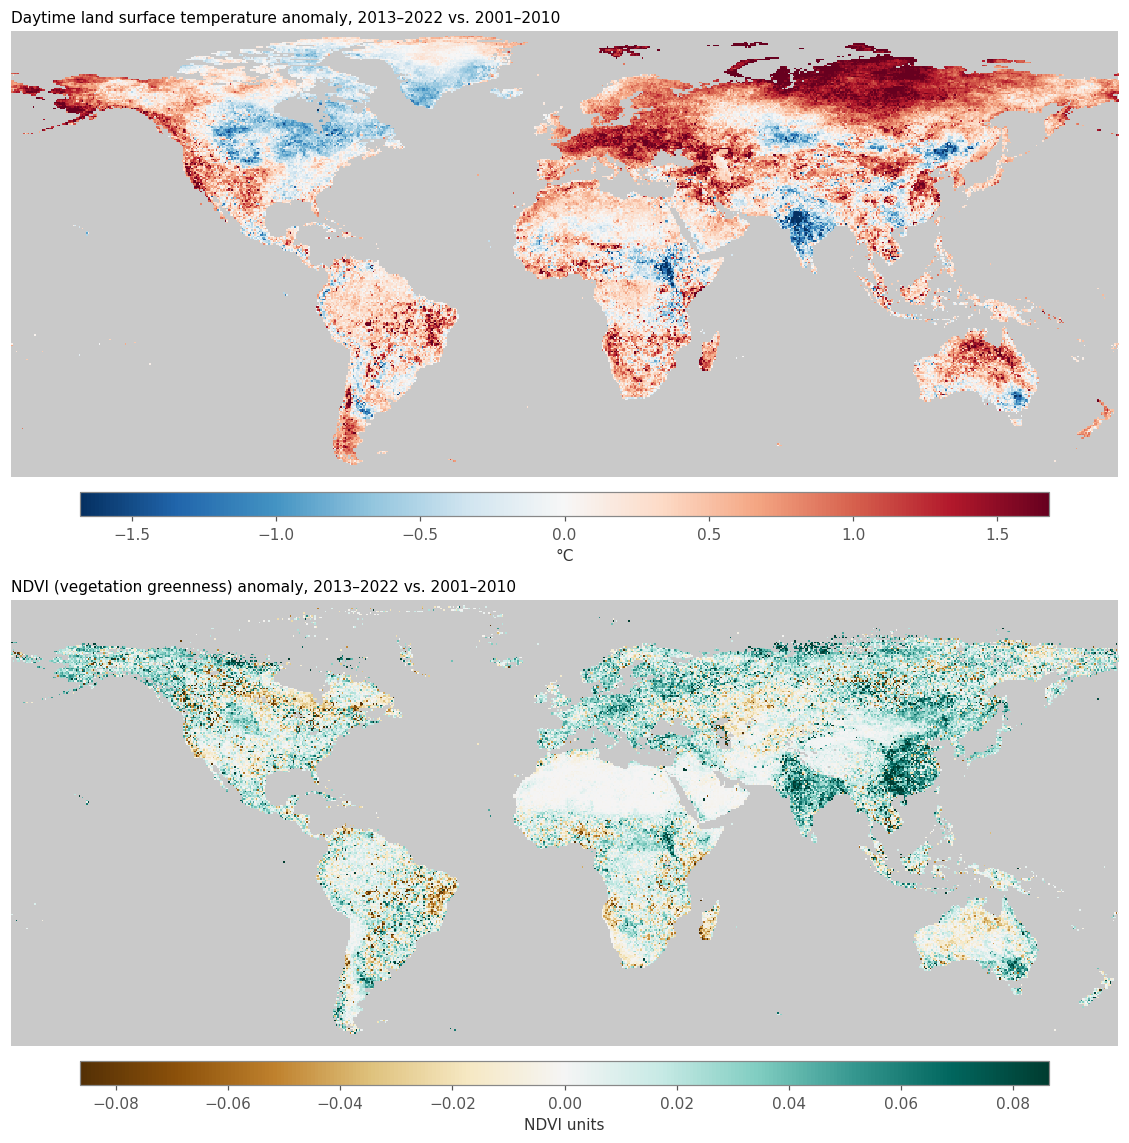

In [14]:
lst_dec = period_mean(YEARS, lst_anom, RECENT)
ndvi_dec = period_mean(YEARS, ndvi_anom, RECENT)

fig, axes = plt.subplots(2, 1, figsize=(11, 10.5))
map_panel(axes[0], lst_dec, tmpl, "RdBu_r", sym_limit(lst_dec),
          "Daytime land surface temperature anomaly, 2013–2022 vs. 2001–2010", "°C")
map_panel(axes[1], ndvi_dec, tmpl, "BrBG", sym_limit(ndvi_dec),
          "NDVI (vegetation greenness) anomaly, 2013–2022 vs. 2001–2010", "NDVI units")
plt.tight_layout()

w = np.cos(np.deg2rad(tmpl.lats))[:, None] * np.ones_like(lst_dec)
def wmean(a):
    ok = np.isfinite(a); return (a[ok] * w[ok]).sum() / w[ok].sum()
print(f"Land-average change: LST {wmean(lst_dec):+.2f} °C, NDVI {wmean(ndvi_dec):+.4f}")
print(f"Share of land pixels warmer: {(lst_dec[np.isfinite(lst_dec)] > 0).mean():.0%}; "
      f"share greener: {(ndvi_dec[np.isfinite(ndvi_dec)] > 0).mean():.0%}")

### Year by year

One map per year, all on the same color scale. These grids are a preview of what an animated or slider-driven
visualization could show. Look for years that stand out: heatwaves, droughts, El Niño years (2015–16).

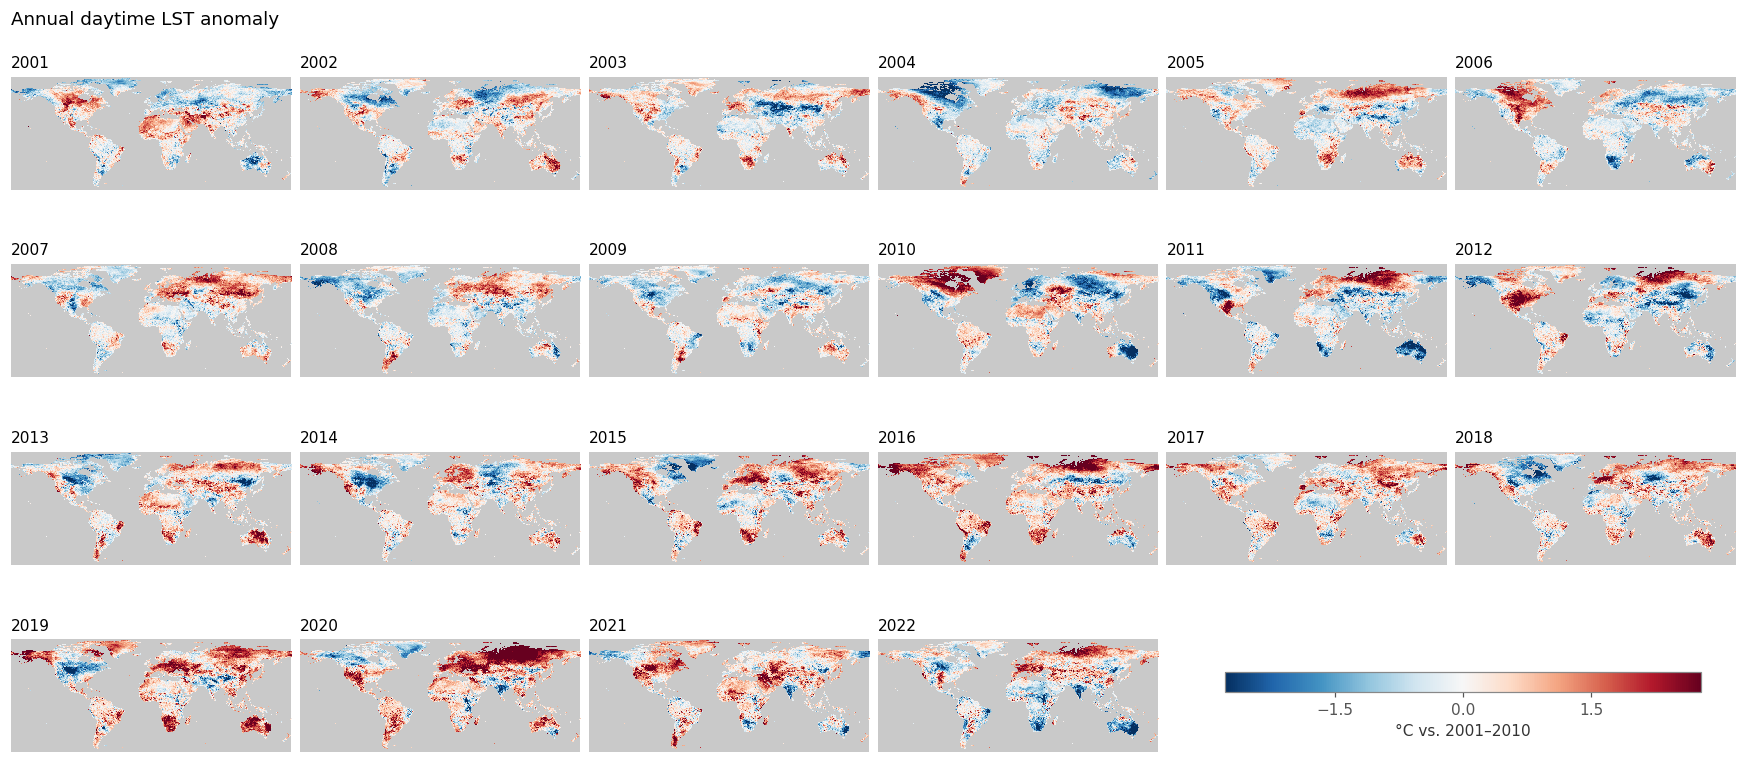

In [15]:
def year_grid(annual, cmap, label, title):
    vlim = sym_limit(annual)
    fig, axes = plt.subplots(4, 6, figsize=(16, 7.2))
    for ax, y, frame in zip(axes.flat, YEARS, annual):
        im = map_panel(ax, frame, tmpl, cmap, vlim, str(y))
    for ax in axes.flat[len(YEARS):]:
        ax.axis("off")
    plt.subplots_adjust(left=0.01, right=0.99, bottom=0.02, wspace=0.03, hspace=0.25, top=0.92)
    cax = fig.add_axes([0.70, 0.12, 0.27, 0.025])
    cb = fig.colorbar(im, cax=cax, orientation="horizontal", label=label)
    cb.locator = plt.MaxNLocator(5, symmetric=True); cb.update_ticks()
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)

year_grid(lst_anom, "RdBu_r", "°C vs. 2001–2010", "Annual daytime LST anomaly")

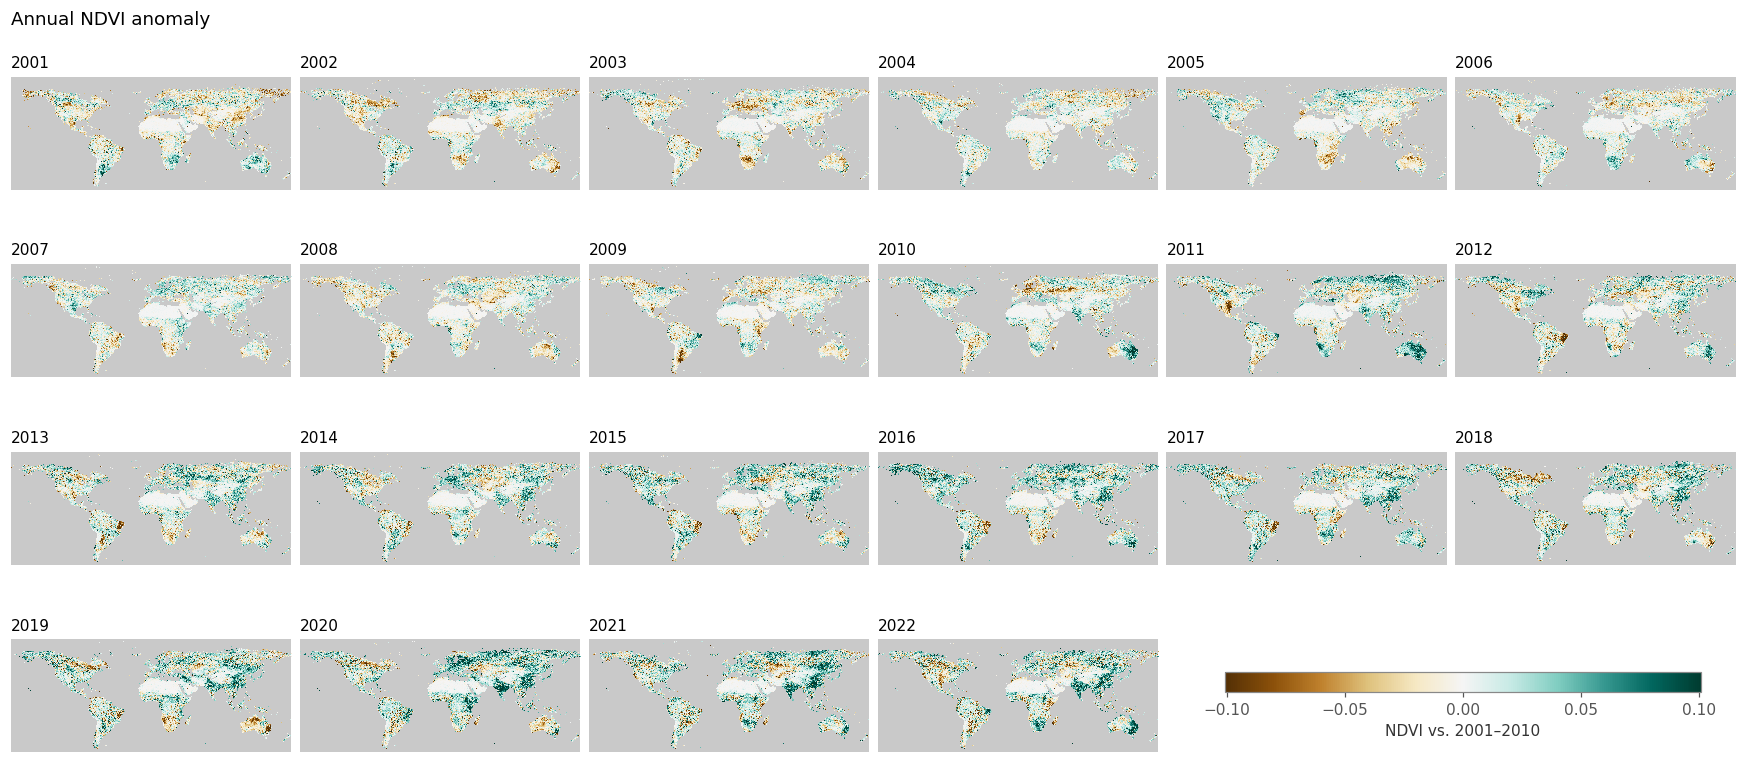

In [16]:
year_grid(ndvi_anom, "BrBG", "NDVI vs. 2001–2010", "Annual NDVI anomaly")

,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
LST anomaly (°C),0.105,0.110,0.008,-0.263,0.114,-0.105,0.194,-0.130,-0.050,0.017,...,0.200,0.103,0.251,0.502,0.28,0.170,0.520,0.664,0.357,-0.107
NDVI anomaly,-0.001,-0.002,-0.003,0.001,-0.000,0.001,0.003,-0.002,-0.002,0.004,...,0.006,0.006,0.008,0.012,0.01,0.007,0.007,0.015,0.012,0.010


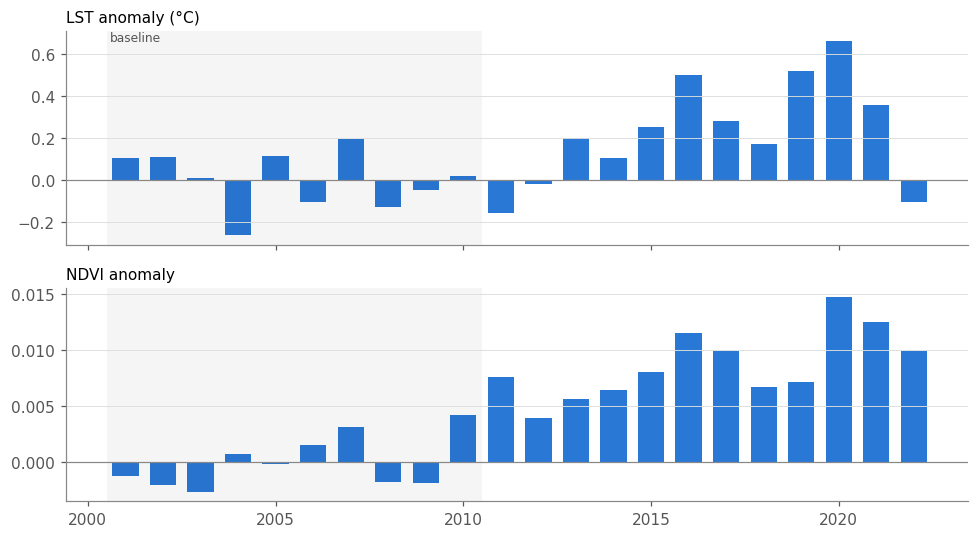

In [17]:
# Land-average anomaly per year (area-weighted) - which years stand out globally?
yearly = pd.DataFrame({"LST anomaly (°C)": [wmean(a) for a in lst_anom],
                       "NDVI anomaly": [wmean(a) for a in ndvi_anom]}, index=YEARS)
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, col, color in zip(axes, yearly.columns, SERIES[:1] * 2):
    ax.bar(yearly.index, yearly[col], color=color, width=0.7)
    ax.axhline(0, color="#888", lw=0.8); ax.set_title(col); ax.grid(axis="y")
    ax.axvspan(BASE[0] - 0.5, BASE[1] + 0.5, color="#000", alpha=0.04, lw=0)
axes[0].text(BASE[0] - 0.4, axes[0].get_ylim()[1], "baseline", va="top", fontsize=8, color="#555")
plt.tight_layout()
yearly.round(3).T

### Trend maps
Least-squares slope per pixel over 2001–2022 (needs ≥ 15 valid years), in units per decade. This shows steady
change rather than one-off spikes, which makes it the best map for "how has vegetation changed over time".

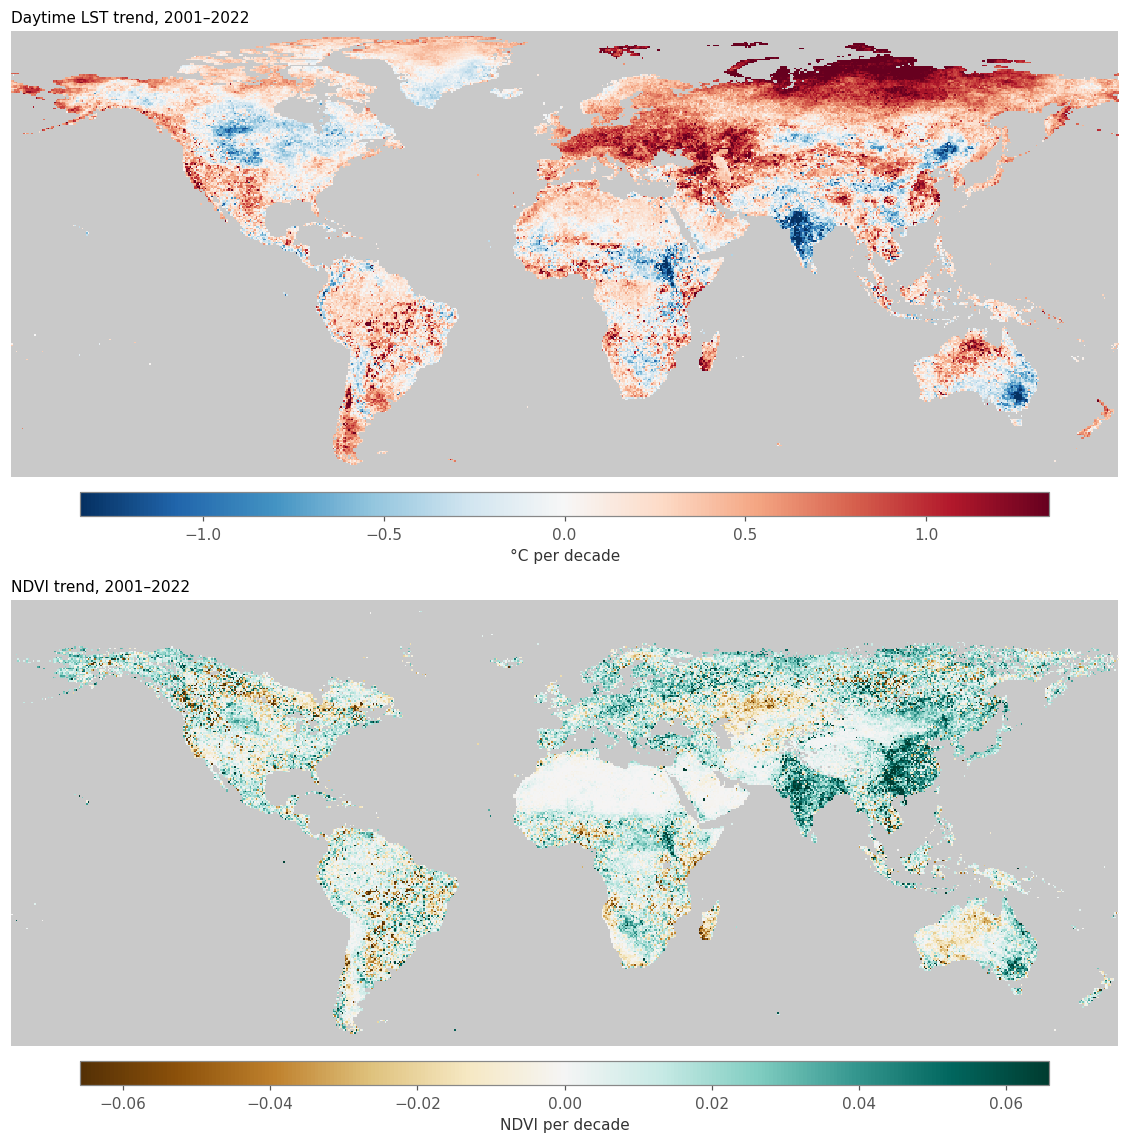

In [18]:
lst_trend = trend_per_decade(YEARS, lst_anom)
ndvi_trend = trend_per_decade(YEARS, ndvi_anom)

fig, axes = plt.subplots(2, 1, figsize=(11, 10.5))
map_panel(axes[0], lst_trend, tmpl, "RdBu_r", sym_limit(lst_trend), "Daytime LST trend, 2001–2022", "°C per decade")
map_panel(axes[1], ndvi_trend, tmpl, "BrBG", sym_limit(ndvi_trend), "NDVI trend, 2001–2022", "NDVI per decade")
plt.tight_layout()

## 2.3 Vegetation coverage: land-cover change

NDVI measures *how green* a pixel is. The yearly **IGBP land-cover** layer (`MODIS_Combined_L3_IGBP_Land_Cover_Type_Annual`,
2001–2024, Terra+Aqua) says *what covers it*: one of 17 classes. To turn classes into coverage percentages:

- fetch each year at **0.1°** (3600×1800; GIBS samples the 500 m product to the nearest pixel, so colors stay exact),
- count classes in 5×5 blocks to get the **fraction of land** in each group per 0.5° cell, on the same grid as LST/NDVI,
- group the classes: **Forest** (5 forest types), **Cropland** (croplands + cropland mosaics),
  **Shrub/savanna/grass**, **Barren**.

Caution: individual pixels can switch class from one year to the next because of classification noise.
So change is measured as the average of the **last 3 years minus the average of the first 3 years**, not one year against another.

**Starting at 2002:** the global time series below shows the shrub/savanna/grass share jumping by about 1.3 percentage points
from 2001 to 2002 and then staying flat. That looks like an inconsistency in the 2001 classification rather than real change,
so comparisons use **2002–2004** as the starting period.

In [19]:
LC = "MODIS_Combined_L3_IGBP_Land_Cover_Type_Annual"
lc_cmap = load_colormap(LC)
LC_LABELS = list(lc_cmap.classes.values())
_lc_keys = np.array(list(lc_cmap.classes.keys()), np.int64)
_lc_sort = np.argsort(_lc_keys)

LC_GROUPS = {
    "Forest": ["Evergreen Needleleaf Forests", "Evergreen Broadleaf Forests", "Deciduous Needleleaf Forests",
               "Deciduous Broadleaf Forests", "Mixed Forests"],
    "Cropland": ["Croplands", "Cropland/Natural Vegetation Mosaics"],
    "Shrub/savanna/grass": ["Closed Shrublands", "Open Shrublands", "Woody Savannas", "Savannas", "Grasslands"],
    "Barren": ["Barren"],
}
NOT_LAND = ["Water Bodies", "Unclassified", "No Data"]
assert all(l in LC_LABELS for g in LC_GROUPS.values() for l in g), LC_LABELS


def get_classes(when, width=3600):
    """Land-cover class index per pixel (index into LC_LABELS; -1 = no data)."""
    rgba = fetch_png(LC, when, GLOBAL, width)
    key = rgb_key(rgba[..., 0], rgba[..., 1], rgba[..., 2])
    sk = _lc_keys[_lc_sort]
    pos = np.clip(np.searchsorted(sk, key), 0, len(sk) - 1)
    return np.where((sk[pos] == key) & (rgba[..., 3] > 0), _lc_sort[pos], -1).astype(np.int8)


def block_count(mask, f=5):
    H, W = mask.shape
    return mask.reshape(H // f, f, W // f, f).sum(axis=(1, 3))


LAND_IDX = [i for i, l in enumerate(LC_LABELS) if l not in NOT_LAND]
GROUP_IDX = {g: [LC_LABELS.index(l) for l in labels] for g, labels in LC_GROUPS.items()}
LC_YEARS = np.array([d.year for d in layer_dates(LC)])
LC_START = 2002                               # 2001 looks inconsistent with later years (see note above)

with ThreadPoolExecutor(4) as ex:
    list(ex.map(lambda y: fetch_png(LC, f"{y}-01-01", GLOBAL, 3600), LC_YEARS))

lc_frac = {g: [] for g in LC_GROUPS}         # group -> (year, 360, 720) fraction of land
for y in LC_YEARS:
    codes = get_classes(f"{y}-01-01")
    land = block_count(np.isin(codes, LAND_IDX))
    for g, idx in GROUP_IDX.items():
        lc_frac[g].append(np.where(land > 0, block_count(np.isin(codes, idx)) / np.maximum(land, 1), np.nan))
    if y == LC_START:                         # dominant class per cell at the start (for 2.4)
        counts = np.stack([block_count(codes == i) for i in range(len(LC_LABELS))])
        dominant_start = np.where(land > 0, counts.argmax(0), -1)
lc_frac = {g: np.stack(v).astype(np.float32) for g, v in lc_frac.items()}
print(f"land cover {LC_YEARS.min()}–{LC_YEARS.max()}, grid {lc_frac['Forest'].shape}")

land cover 2001–2024, grid (24, 360, 720)


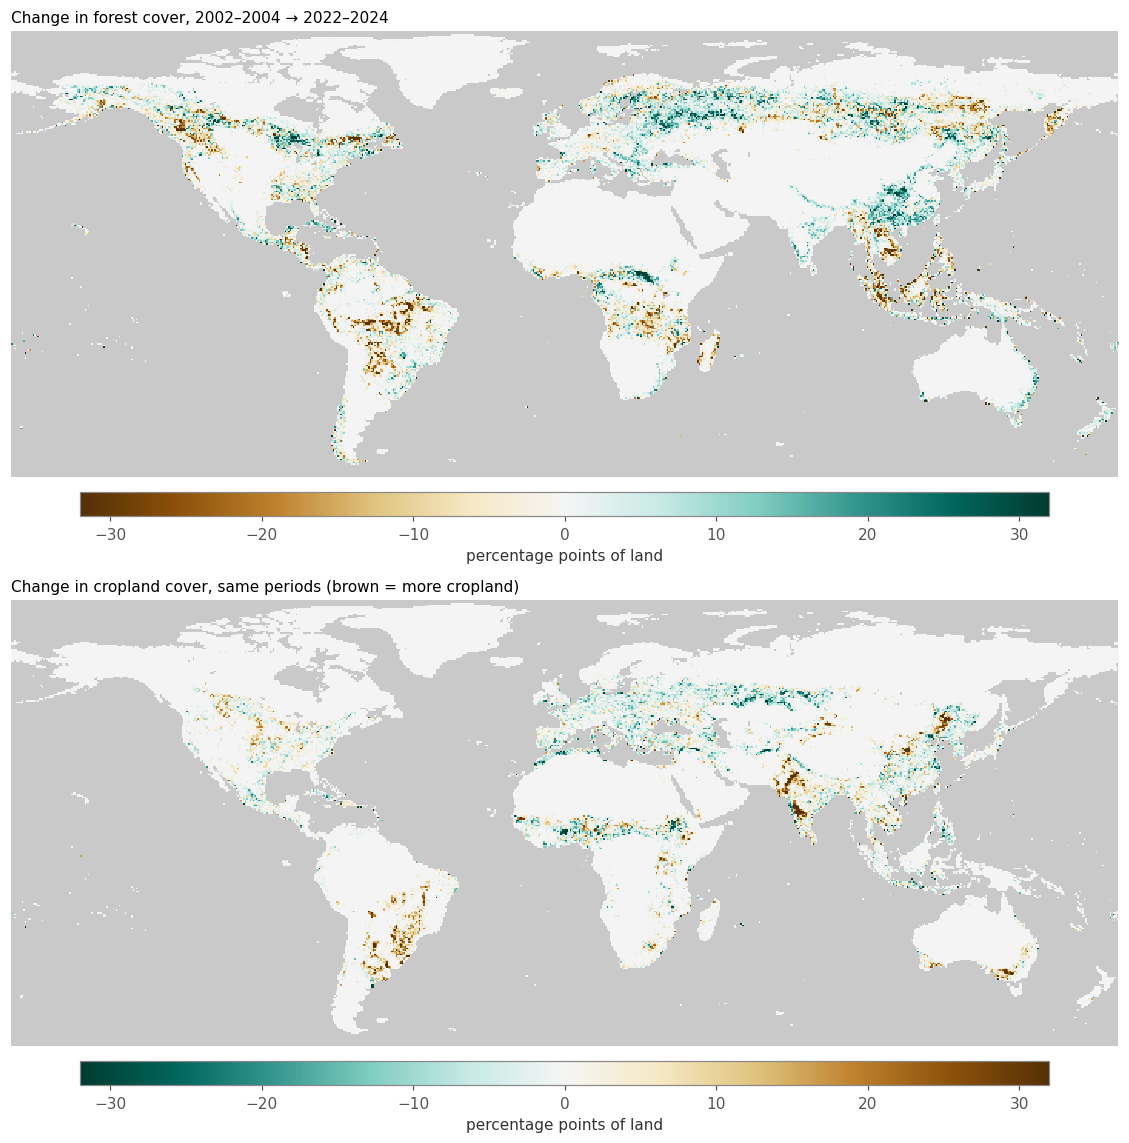

In [20]:
def lc_change(group, n=3):
    f = lc_frac[group][LC_YEARS >= LC_START]
    return 100 * (np.nanmean(f[-n:], axis=0) - np.nanmean(f[:n], axis=0))   # percentage points

forest_change = lc_change("Forest")
crop_change = lc_change("Cropland")
first, last = LC_YEARS[LC_YEARS >= LC_START][:3], LC_YEARS[-3:]
vlim = sym_limit(forest_change, crop_change, q=99.5)

fig, axes = plt.subplots(2, 1, figsize=(11, 10.5))
map_panel(axes[0], forest_change, tmpl, "BrBG", vlim,
          f"Change in forest cover, {first[0]}–{first[-1]} → {last[0]}–{last[-1]}", "percentage points of land")
map_panel(axes[1], crop_change, tmpl, "BrBG_r", vlim,
          f"Change in cropland cover, same periods (brown = more cropland)", "percentage points of land")
plt.tight_layout()

,Forest,Cropland,Shrub/savanna/grass,Barren
2001,16.06,9.01,46.73,14.29
2024,16.23,8.94,48.69,13.56


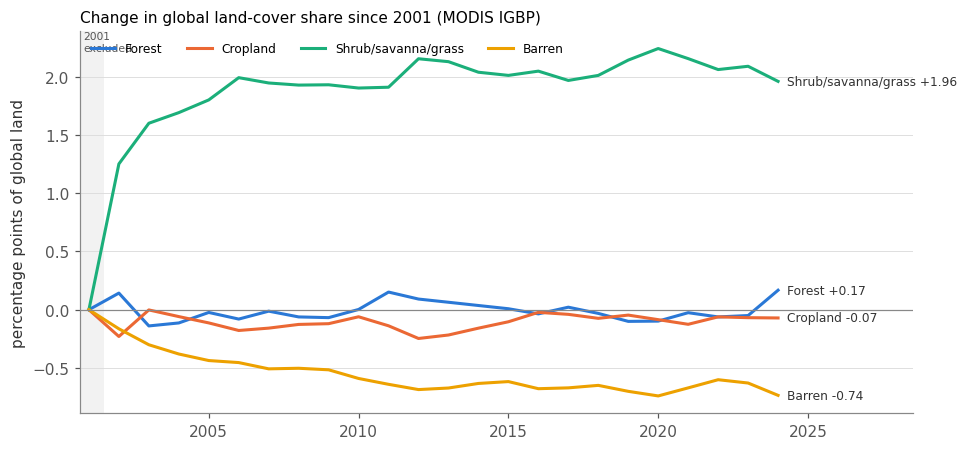

In [21]:
# Global share of land in each cover group, as change since the first year (area-weighted)
land_w = np.cos(np.deg2rad(tmpl.lats))[:, None]
def global_share(frac):
    return np.array([np.nansum(f * land_w) / np.nansum(np.isfinite(f) * land_w) for f in frac])

share = pd.DataFrame({g: 100 * global_share(lc_frac[g]) for g in LC_GROUPS}, index=LC_YEARS)
delta = share - share.iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.2))
for (g, s), color in zip(delta.items(), SERIES):
    ax.plot(s.index, s.values, color=color, lw=2, label=g)
    ax.annotate(f"{g} {s.iloc[-1]:+.2f}", (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color="#333")
ax.axhline(0, color="#888", lw=0.8)
ax.axvspan(LC_YEARS[0] - 0.3, LC_START - 0.5, color="#000", alpha=0.05, lw=0)
ax.text(LC_YEARS[0] - 0.2, ax.get_ylim()[1], "2001\nexcluded", va="top", fontsize=7, color="#555")
ax.set_xlim(LC_YEARS[0] - 0.3, LC_YEARS[-1] + 4.5)
ax.set_ylabel("percentage points of global land"); ax.grid(axis="y")
ax.set_title(f"Change in global land-cover share since {LC_YEARS[0]} (MODIS IGBP)")
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=4)
plt.tight_layout()
share.iloc[[0, -1]].round(2)

## 2.4 Comparison: temperature vs. vegetation

Three views of how the two are related:

1. **Year-to-year correlation per pixel.** Does a hot year go with a brown year?
   - *Negative r* (orange): hot years are browner. These are **water-limited** regions where heat means drought stress
     (and where less vegetation means less evaporative cooling, which raises LST further).
   - *Positive r* (purple): warm years are greener. These are **energy-limited** regions (cold places) where warmth
     lengthens the growing season.
2. **Trend vs. trend.** Have pixels that browned or lost forest also warmed?
3. **By land-cover type, and in hotspot regions.**

,median r,share negative
S. extratropics,-0.64,0.91
Tropics,-0.30,0.70
N. midlatitudes,-0.08,0.57
Boreal/Arctic,0.31,0.17


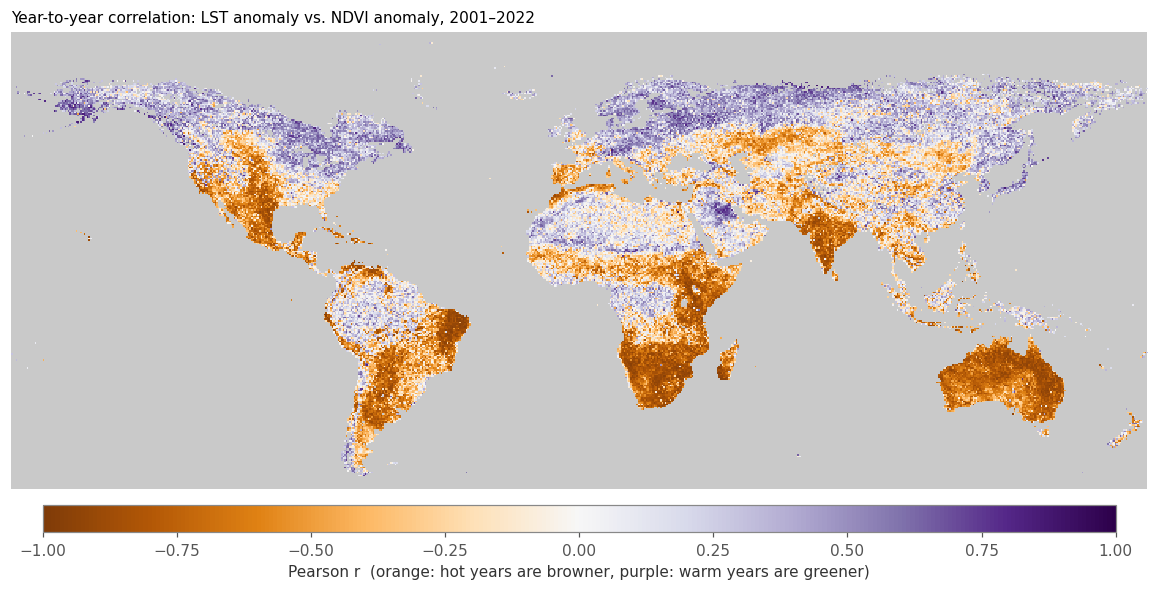

In [22]:
r = pixel_corr(lst_anom, ndvi_anom)
fig, ax = plt.subplots(figsize=(11, 5.6))
map_panel(ax, r, tmpl, "PuOr", 1.0, "Year-to-year correlation: LST anomaly vs. NDVI anomaly, 2001–2022",
          "Pearson r  (orange: hot years are browner, purple: warm years are greener)")
plt.tight_layout()

lat2d = np.broadcast_to(tmpl.lats[:, None], r.shape)
bands = pd.cut(lat2d[np.isfinite(r)], [-60, -23.5, 23.5, 50, 85], labels=["S. extratropics", "Tropics", "N. midlatitudes", "Boreal/Arctic"])
pd.Series(r[np.isfinite(r)]).groupby(bands, observed=True).agg(["median", lambda s: (s < 0).mean()]).set_axis(
    ["median r", "share negative"], axis=1).round(2)

**Trend vs. trend.** Each hexagon counts 0.5° cells. The orange line is the median LST trend within fixed-width
x-bins (shown only for bins with ≥ 30 cells). The forest panel uses only **forested cells** (≥ 20% forest at the start or end);
otherwise the many deserts and croplands with exactly 0 change would dominate it.

Forested cells that lost >10 pp forest: 2,553, median LST trend +0.35 °C/dec; forested cells with stable cover: 4,819, median +0.25 °C/dec


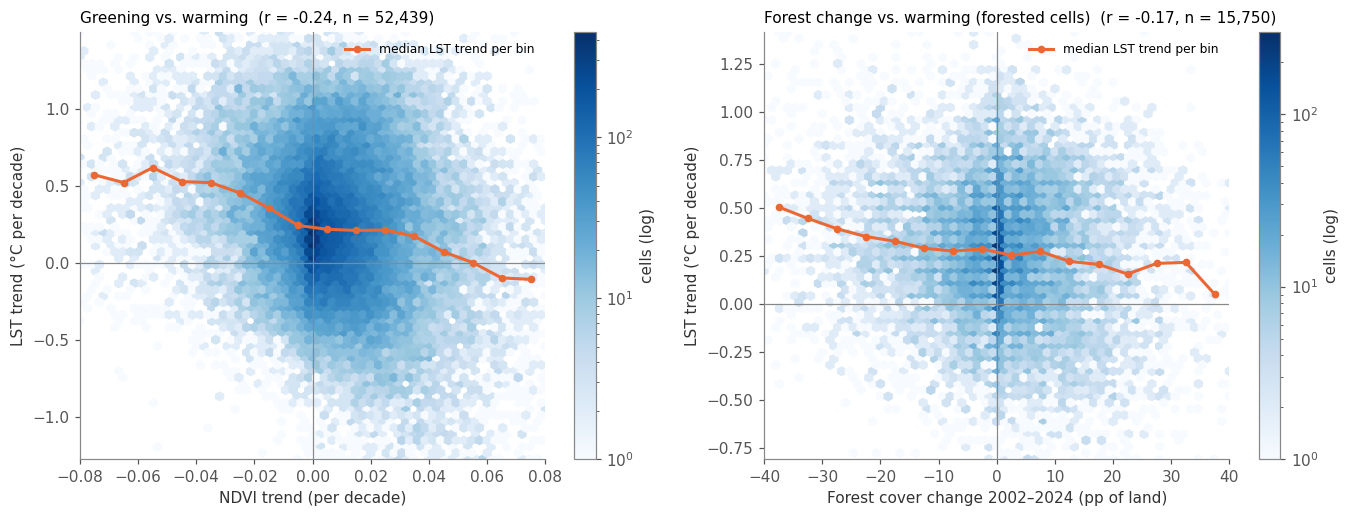

In [23]:
forest_start = 100 * np.nanmean(lc_frac["Forest"][LC_YEARS >= LC_START][:3], axis=0)
forested = (forest_start >= 20) | (forest_start + forest_change >= 20)

def trend_hexbin(ax, x, y, mask, xl, title, xlim, step):
    ok = mask & np.isfinite(x) & np.isfinite(y)
    xs, ys = x[ok], y[ok]
    ylim = np.percentile(ys, [0.5, 99.5])
    hb = ax.hexbin(xs, ys, gridsize=60, bins="log", mincnt=1, cmap="Blues", extent=(*xlim, *ylim))
    ax.axhline(0, color="#888", lw=0.8); ax.axvline(0, color="#888", lw=0.8)
    edges = np.arange(xlim[0], xlim[1] + step / 2, step)
    mids, meds = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        sel = (xs >= a) & (xs < b)
        if sel.sum() >= 30:
            mids.append((a + b) / 2); meds.append(np.median(ys[sel]))
    ax.plot(mids, meds, color="#eb6834", lw=2, marker="o", ms=4, label="median LST trend per bin")
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xlabel(xl); ax.set_ylabel("LST trend (°C per decade)")
    ax.set_title(f"{title}  (r = {np.corrcoef(xs, ys)[0, 1]:+.2f}, n = {ok.sum():,})")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    plt.colorbar(hb, ax=ax, label="cells (log)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
trend_hexbin(axes[0], ndvi_trend, lst_trend, np.ones_like(forested), "NDVI trend (per decade)",
             "Greening vs. warming", (-0.08, 0.08), 0.01)
trend_hexbin(axes[1], forest_change, lst_trend, forested, f"Forest cover change {first[0]}–{last[-1]} (pp of land)",
             "Forest change vs. warming (forested cells)", (-40, 40), 5)
plt.tight_layout()

loss, stable = forested & (forest_change < -10), forested & (np.abs(forest_change) < 2)
print(f"Forested cells that lost >10 pp forest: {loss.sum():,}, median LST trend {np.nanmedian(lst_trend[loss]):+.2f} °C/dec; "
      f"forested cells with stable cover: {stable.sum():,}, median {np.nanmedian(lst_trend[stable]):+.2f} °C/dec")

,cells,LST trend (°C/dec),NDVI trend (/dec),r (LST vs NDVI)
class,,,,
Barren,7305,0.193,0.001,0.032
Evergreen Broadleaf Forests,4248,0.226,0.005,0.077
Open Shrublands,5124,0.319,0.006,-0.445
Grasslands,10572,0.153,0.007,-0.401
Evergreen Needleleaf Forests,1387,0.391,0.009,0.361
Savannas,7071,0.219,0.009,-0.073
Permanent Wetlands,379,0.540,0.010,0.372
Woody Savannas,5293,0.219,0.010,0.217
Deciduous Broadleaf Forests,873,0.166,0.010,0.245


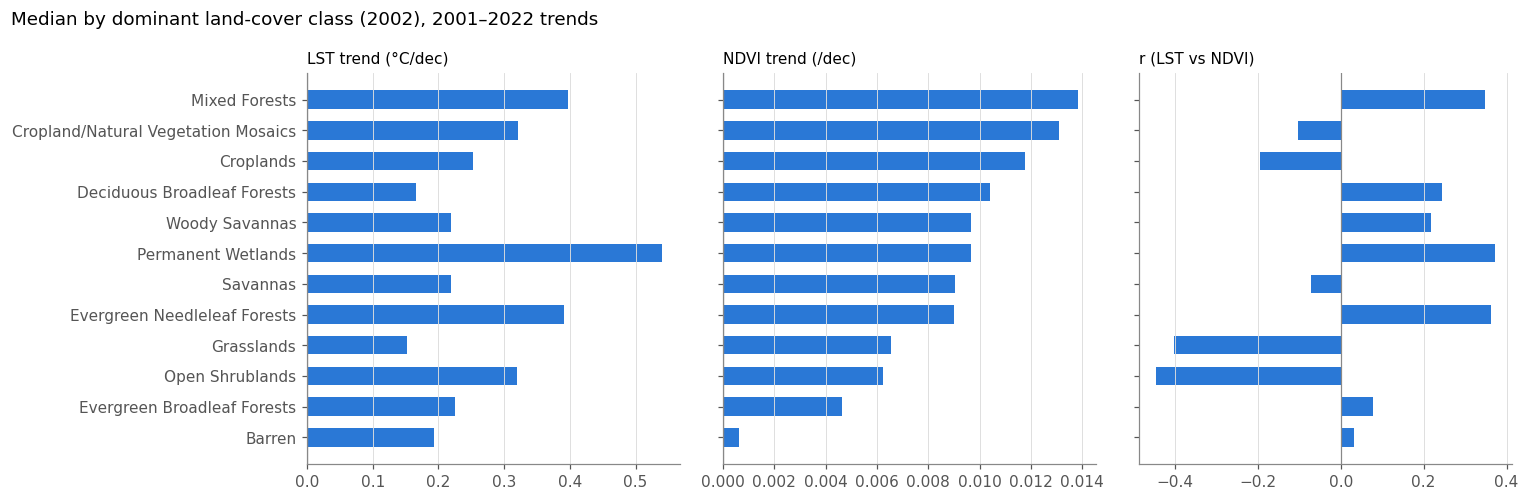

In [24]:
# By dominant land-cover class at the start: median trends (separate panels, one measure each)
rows = []
for i, label in enumerate(LC_LABELS):
    if label in NOT_LAND or label == "Permanent Snow and Ice":
        continue
    m = (dominant_start == i) & np.isfinite(lst_trend) & np.isfinite(ndvi_trend)
    if m.sum() >= 200:
        rows.append({"class": label, "cells": int(m.sum()),
                     "LST trend (°C/dec)": np.median(lst_trend[m]), "NDVI trend (/dec)": np.median(ndvi_trend[m]),
                     "r (LST vs NDVI)": np.nanmedian(r[m])})
by_class = pd.DataFrame(rows).set_index("class").sort_values("NDVI trend (/dec)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, col in zip(axes, ["LST trend (°C/dec)", "NDVI trend (/dec)", "r (LST vs NDVI)"]):
    ax.barh(by_class.index, by_class[col], color=SERIES[0], height=0.6)
    ax.axvline(0, color="#888", lw=0.8); ax.set_title(col); ax.grid(axis="x")
fig.suptitle(f"Median by dominant land-cover class ({LC_START}), 2001–2022 trends", x=0.01, ha="left")
plt.tight_layout()
by_class.round(3)

### Hotspot regions
Candidate regions picked from known land-change stories. Their outlines are drawn on the map below; check that they
sit on the strongest features in the maps above.

Each region gets its own column: LST anomaly on top, NDVI anomaly below. These are two separate charts
with a shared year axis (not a dual-axis chart).

,LST trend °C/dec,NDVI trend /dec,forest change pp,r (yearly LST vs NDVI)
region,,,,
Amazon deforestation arc,0.433,-0.002,-6.428,-0.414
Sahel,-0.013,0.007,0.018,-0.080
Indo-Gangetic Plain,-0.281,0.030,1.092,-0.623
Eastern China,0.308,0.037,5.018,0.477
California,0.572,-0.004,-1.838,-0.720
Siberia,0.699,0.011,0.207,0.680
SE Australia,-0.514,0.019,1.666,-0.877


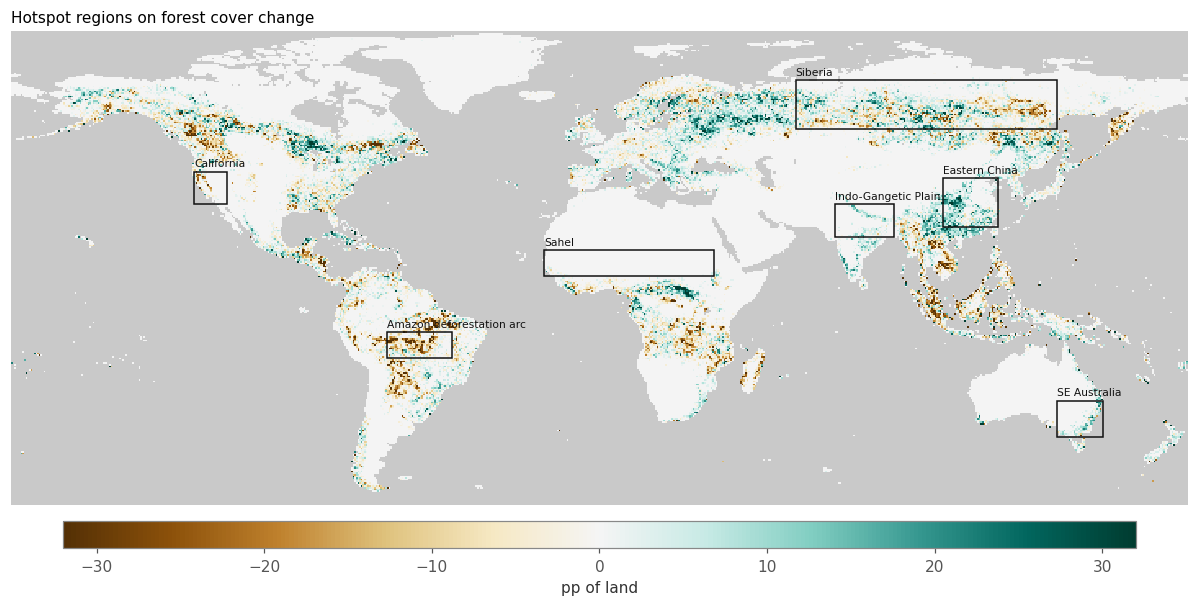

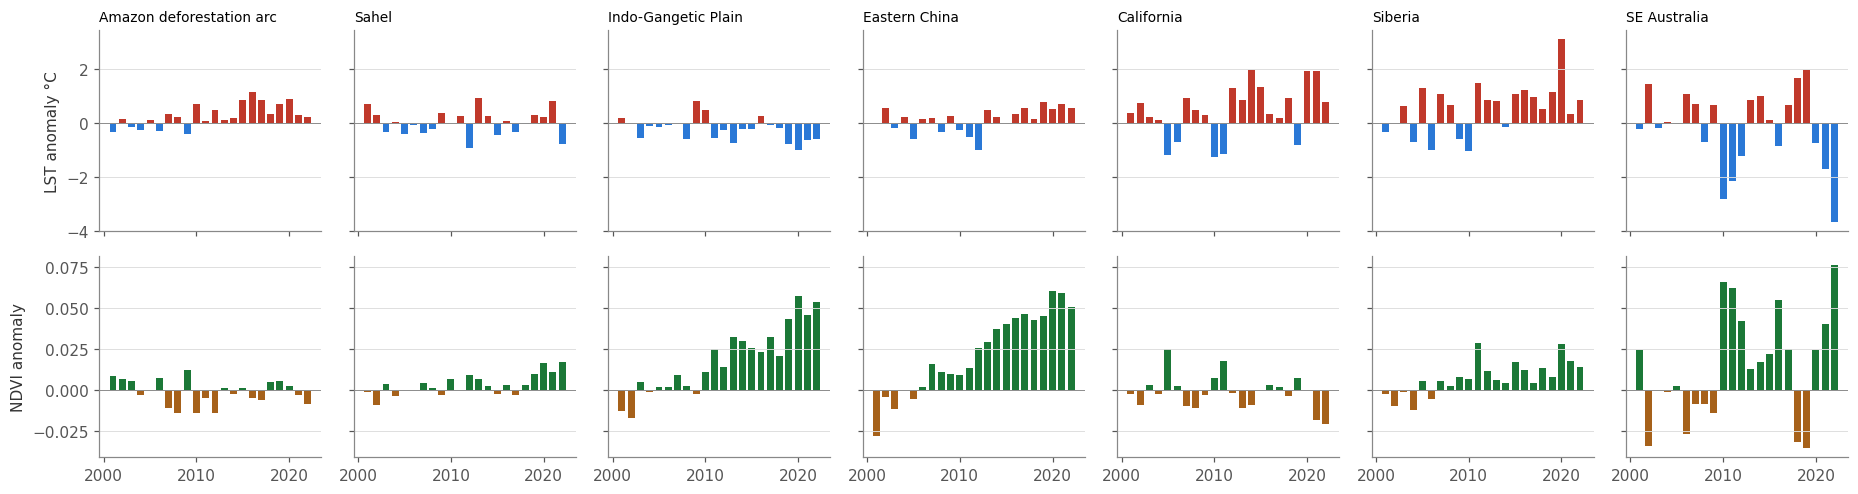

In [25]:
REGIONS = {
    "Amazon deforestation arc": ((-15, -7), (-65, -45)),
    "Sahel": ((10, 18), (-17, 35)),
    "Indo-Gangetic Plain": ((22, 32), (72, 90)),
    "Eastern China": ((25, 40), (105, 122)),
    "California": ((32, 42), (-124, -114)),
    "Siberia": ((55, 70), (60, 140)),
    "SE Australia": ((-39, -28), (140, 154)),
}

fig, ax = plt.subplots(figsize=(11, 5.6))
map_panel(ax, forest_change, tmpl, "BrBG", vlim, "Hotspot regions on forest cover change", "pp of land", boxes=REGIONS)
plt.tight_layout()

fig, axes = plt.subplots(2, len(REGIONS), figsize=(17, 4.6), sharex=True, sharey="row")
summary = []
for j, (name, (lat, lon)) in enumerate(REGIONS.items()):
    s_lst = region_mean_series(YEARS, lst_anom, tmpl, lat, lon)
    s_ndvi = region_mean_series(YEARS, ndvi_anom, tmpl, lat, lon)
    for ax, s in zip(axes[:, j], [s_lst, s_ndvi]):
        ax.bar(s.index, s.values, color=np.where(s.values >= 0, "#c0392b", "#2a78d6") if s is s_lst
               else np.where(s.values >= 0, "#1b7837", "#a6611a"), width=0.75)
        ax.axhline(0, color="#888", lw=0.6); ax.grid(axis="y")
    axes[0, j].set_title(name, fontsize=9)
    sub = Grid(LST, None, forest_change, tmpl.lats, tmpl.lons).sel(lat=lat, lon=lon)
    summary.append({"region": name,
                    "LST trend °C/dec": np.polyfit(YEARS, s_lst.values, 1)[0] * 10,
                    "NDVI trend /dec": np.polyfit(YEARS, s_ndvi.values, 1)[0] * 10,
                    "forest change pp": sub.mean(),
                    "r (yearly LST vs NDVI)": s_lst.corr(s_ndvi)})
axes[0, 0].set_ylabel("LST anomaly °C"); axes[1, 0].set_ylabel("NDVI anomaly")
plt.tight_layout()
pd.DataFrame(summary).set_index("region").round(3)

## Phase 2 findings

All comparisons are 2013–2022 vs. 2001–2010 (anomalies) or 2001–2022 (trends), MODIS Terra daytime LST and NDVI
on a 0.5° grid, plus IGBP land cover for 2002–2024.

**Anomalies**
- Land is **+0.29 °C warmer** on average (daytime LST), and **62%** of land pixels warmed. The strongest warming is in
  Siberia and Eastern Europe, the southern Amazon, and the western US. **India, East Africa, SE Australia and central Canada cooled.**
- NDVI rose in **69%** of pixels (global greening). By far the largest increases are in **India and eastern China**.
- 2016, 2019 and 2020 were the warmest years overall. 2022 dips below the baseline. It was a La Niña year, but it's
  worth checking whether early orbit drift contributes before relying on that year.

**Vegetation vs. temperature**
- **Hot years are brown years in dry regions:** the year-to-year correlation is negative in 91% of southern-extratropical pixels
  (median r = −0.64) and 70% of tropical pixels. It **flips to positive in the boreal zone** (median r = +0.31), where warmth means a longer growing season.
- **Browning goes with warming:** pixels with the most negative NDVI trends warmed about 0.55 °C/decade, compared with about 0 for the
  fastest-greening pixels (r = −0.24).
- **Forest loss goes with extra warming:** forested cells that lost >10 percentage points of forest warmed +0.35 °C/decade vs. +0.25 °C/decade
  where cover was stable. The **Amazon deforestation arc** combines −6.4 pp forest, +0.43 °C/decade and slight browning.
- **India and China both greened, but in opposite temperature directions:** India cooled (−0.28 °C/decade, irrigated cropland)
  while eastern China warmed (+0.31 °C/decade, afforestation + cropland, +5 pp forest).

**Candidate stories for Phase 3**
1. **"Hot years, brown years"**: a global map you scrub through year by year, with LST and NDVI anomalies side by side and the
   correlation map as the key. Clicking a region shows its paired anomaly bars. This uses both datasets most directly.
2. **"What happens when the forest goes"**: the Amazon arc (or SE Asia) zoomed in at higher resolution (≈0.05°), with a forest-cover
   slider over time linked to LST. This is the clearest single story about cause and effect.
3. **"Two ways to green"**: India vs. China, where similar greening comes with opposite temperature trends.

**Caveats to carry forward:** correlation does not prove causation (drought both browns and heats the land); 0.5° cells blur
deforestation patches; land-cover classes are noisy from year to year; use data only up to 2022 because of orbit drift.